In [55]:
%pip install -q tensorflow opencv-python matplotlib scikit-learn seaborn pillow kaggle
%pip install -q streamlit imutils

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [56]:
import sys
import tensorflow as tf
import importlib.util
import importlib.metadata

print("========== PYTHON INFORMATION ==========")

print("Python version:", sys.version)
print("Python location:", sys.executable)

print("\n========== TENSORFLOW INFORMATION ==========")

print("TensorFlow module:", tf)
print("TensorFlow location:", getattr(tf, "__file__", None))
print("TensorFlow version:", getattr(tf, "__version__", "Not Available"))

print("\n========== PACKAGE INFORMATION ==========")

try:
    print("Installed TensorFlow:", importlib.metadata.version("tensorflow"))
except Exception as e:
    print("Package error:", e)

print("\n========== MODULE SPECIFICATION ==========")

print(importlib.util.find_spec("tensorflow"))

========== PYTHON INFORMATION ==========
Python version: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]
Python location: c:\Users\reyan\anaconda3\python.exe

========== TENSORFLOW INFORMATION ==========
TensorFlow module: <module 'tensorflow' (namespace) from ['c:\\Users\\reyan\\anaconda3\\Lib\\site-packages\\tensorflow']>
TensorFlow location: None
TensorFlow version: Not Available

========== PACKAGE INFORMATION ==========
Installed TensorFlow: 2.18.0

========== MODULE SPECIFICATION ==========
ModuleSpec(name='tensorflow', loader=<_frozen_importlib_external.NamespaceLoader object at 0x000002BBE3E2C860>, submodule_search_locations=_NamespacePath(['c:\\Users\\reyan\\anaconda3\\Lib\\site-packages\\tensorflow']))


In [57]:
import os
import pathlib
import subprocess

# Define dataset directory
DATA_DIR = pathlib.Path("dataset")

# Create dataset folder if it doesn't exist
DATA_DIR.mkdir(parents=True, exist_ok=True)


# Function to locate dataset folders
def find_class_root(base):

    for p in [base] + [d for d in base.rglob("*") if d.is_dir()]:

        if (p / "with_mask").is_dir() and (p / "without_mask").is_dir():
            return p

    return None


# Check whether dataset already exists
root = find_class_root(DATA_DIR)

# Download dataset if not found
if root is None:

    print("Dataset not found. Downloading from Kaggle...")

    try:
        subprocess.run(
            [
                "kaggle",
                "datasets",
                "download",
                "-d", "omkargurav/face-mask-dataset",
                "-p", str(DATA_DIR),
                "--unzip"
            ],
            check=True
        )

    except (subprocess.CalledProcessError, FileNotFoundError) as e:
        raise RuntimeError(
            "Kaggle download failed. Check Kaggle CLI installation "
            "and API credentials."
        ) from e

# Locate dataset again
root = find_class_root(DATA_DIR)

# Final validation
if root is None:

    raise FileNotFoundError(
        "Dataset folders not found. Expected with_mask and without_mask."
    )

DATA_DIR = root

print("\nDataset successfully located!")
print("Dataset location:", DATA_DIR.resolve())

print("With mask folder:", (DATA_DIR / "with_mask").exists())
print("Without mask folder:", (DATA_DIR / "without_mask").exists())


Dataset successfully located!
Dataset location: C:\Users\reyan\OneDrive\Desktop\project of ibm\dataset\data
With mask folder: True
Without mask folder: True


In [58]:
from pathlib import Path

image_path = Path(r"C:\Users\reyan\OneDrive\Desktop\project of ibm\Mask Versus No Mask_ Outdoor Portrait Comparison.png")

print(image_path.exists())

True


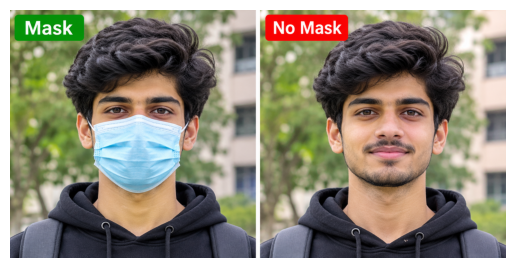

In [59]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(str(image_path))

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.axis("off")
plt.show()

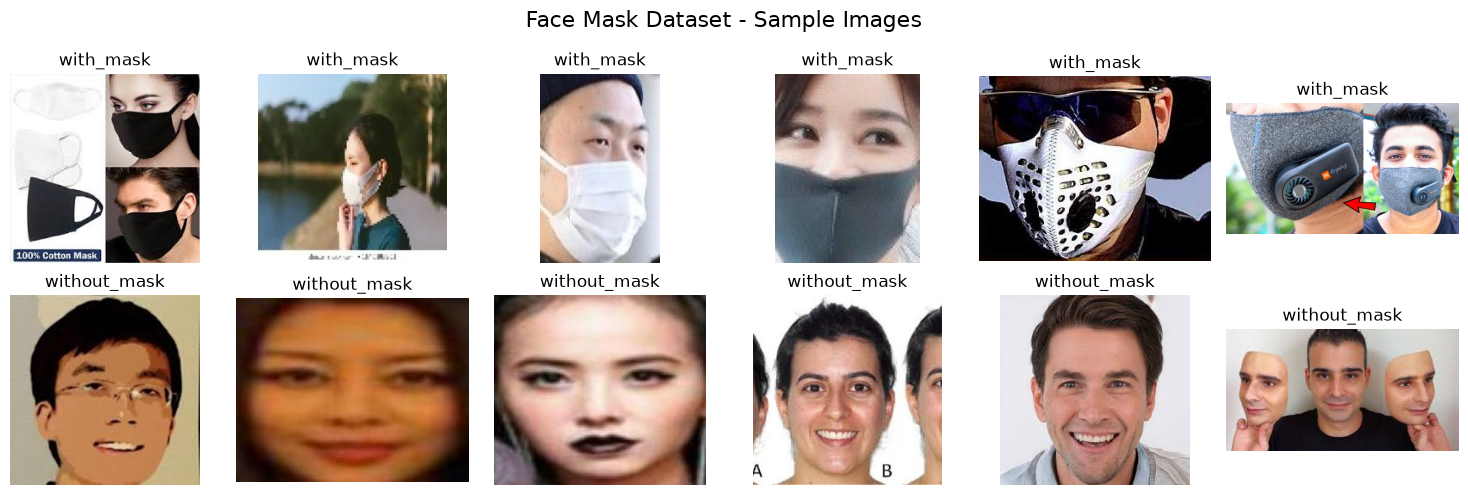

In [60]:
def show_samples(n=6):

    fig, axes = plt.subplots(
        2, n,
        figsize=(2.5*n, 5),
        squeeze=False
    )

    for r, (cls, d) in enumerate(class_dirs.items()):

        # Get supported image files
        files = [
            f for f in d.iterdir()
            if f.is_file() and f.suffix.lower() in IMG_EXT
        ]

        if not files:
            print("No images found in:", cls)
            continue

        # Select random images
        samples = random.sample(files, min(n, len(files)))

        for c in range(n):

            ax = axes[r, c]

            if c < len(samples):

                img = cv2.imread(str(samples[c]))

                if img is not None:

                    img = cv2.cvtColor(
                        img,
                        cv2.COLOR_BGR2RGB
                    )

                    ax.imshow(img)
                    ax.set_title(cls)

                else:
                    ax.set_title("Corrupted Image")

            else:
                ax.set_visible(False)

            ax.axis("off")

    plt.suptitle(
        "Face Mask Dataset - Sample Images",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


import random

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
class_dirs = {
    cls: DATA_DIR / cls
    for cls in ("with_mask", "without_mask")
}

show_samples(n=6)

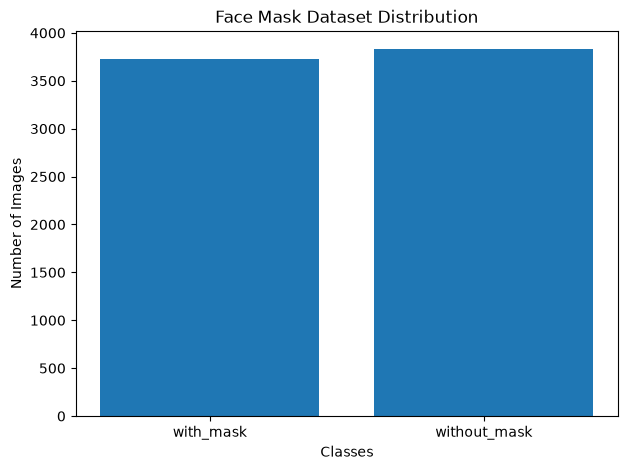

{'with_mask': 3725, 'without_mask': 3828}


In [61]:
class_counts = {}

for cls, folder in class_dirs.items():

    count = sum(
        1 for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in IMG_EXT
    )

    class_counts[cls] = count

plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Face Mask Dataset Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.show()

print(class_counts)

In [62]:
import numpy as np
import tensorflow as tf
from tensorflow import keras, data as tf_data
from tensorflow.keras import layers
from tensorflow import data as tf_data
from tensorflow import data as tf_data
from keras import layers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Collect only readable image files (some datasets contain corrupt files)
def valid_images(d):
    out = []
    for f in d.iterdir():
        if f.suffix.lower() in IMG_EXT:
            out.append(str(f))
    return out

class_root = find_class_root(DATA_DIR)
if class_root is None:
    raise FileNotFoundError(
        f"Could not find 'with_mask' and 'without_mask' folders under {DATA_DIR.resolve()}. "
        "Run cell 2 again and check that the dataset was downloaded and extracted."
    )
DATA_DIR = class_root

paths, labels = [], []
for label, cls in enumerate(["with_mask", "without_mask"]):
    class_dir = DATA_DIR / cls
    ps = valid_images(class_dir)
    paths += ps; labels += [label] * len(ps)

paths = np.array(paths); labels = np.array(labels)
idx = np.random.permutation(len(paths))
paths, labels = paths[idx], labels[idx]

n = len(paths)
n_train, n_val = int(0.70 * n), int(0.15 * n)
splits = {
    "train": (paths[:n_train], labels[:n_train]),
    "val":   (paths[n_train:n_train + n_val], labels[n_train:n_train + n_val]),
    "test":  (paths[n_train + n_val:], labels[n_train + n_val:]),
}
print({k: len(v[0]) for k, v in splits.items()})

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape((*IMG_SIZE, 3))
    return img, tf.cast(label, tf.float32)

def make_ds(split, training=False):
    p, l = splits[split]
    ds = tf.data.Dataset.from_tensor_slices((p, l))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors()          # skip any corrupt image
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Fix TensorFlow submodule access and define Keras symbols

SEED = 42

# Build datasets
train_ds = make_ds("train", training=True)
val_ds = make_ds("val")
test_ds = make_ds("test")

# Optional sanity check
print("Train:", train_ds.cardinality().numpy())
print("Validation:", val_ds.cardinality().numpy())
print("Test:", test_ds.cardinality().numpy())

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")

ImportError: cannot import name 'keras' from 'tensorflow' (unknown location)

In [ ]:
# Visualise augmentation on one training image
batch_imgs, batch_lbls = next(iter(train_ds))
plt.figure(figsize=(12, 3))
for i in range(5):
    ax = plt.subplot(1, 5, i + 1)
    aug = data_augmentation(tf.expand_dims(batch_imgs[0], 0), training=True)[0]
    plt.imshow(np.clip(aug.numpy().astype("uint8"), 0, 255)); plt.axis("off")
plt.suptitle("Augmented versions of the same image"); plt.show()